# Methanol isotherms on Na-EMT and K-EMT
Processes the FTIR spectra recorded during stepwise methanol dosing on Na-EMT and K-EMT. For each sample, the baseline is corrected, the CH stretching band is integrated and its area is plotted against the equivalent pressure to give an adsorption isotherm.

### Setup
Imports the libraries, sets the Matplotlib defaults (live SVG text, Segoe UI font, label and tick sizes, resolution) and defines three helpers: `save_area_sheet` writes one or several tables to an Excel sheet, `add_minor_ticks` adds minor ticks and removes the top and right axes, and `find_linear_range` returns the number of points before saturation. It also sets the `data` folder path.

In [110]:
import spectrochempy as scp
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
from scipy import stats
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from openpyxl.utils import get_column_letter
from openpyxl.styles import Font
import re
from scipy.signal import find_peaks

mpl.rcParams.update({
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI"],
    "axes.unicode_minus": True,
    "axes.labelsize": 20,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})


def save_area_sheet(tables, sheet_name, path, gap=1):
    """Write one table, or several side by side, to a named sheet of an Excel workbook.

    tables: a DataFrame, or a dict {label: DataFrame}. With a dict, each table gets a
            bold label above it and the tables are separated by `gap` empty columns.
    """
    path = Path(path)
    mode = "a" if path.exists() else "w"
    kwargs = {"if_sheet_exists": "replace"} if mode == "a" else {}

    labelled = isinstance(tables, dict)
    if not labelled:
        tables = {None: tables}

    parts, starts, col = [], {}, 1
    for label, t in tables.items():
        if parts and gap:
            spacer = {" " * (len(parts) + 1): [""] * len(t)}        # unique blank header
            parts.append(pd.DataFrame(spacer))
            col += gap
        starts[label] = col
        parts.append(t.reset_index(drop=True))
        col += t.shape[1]
    combined = pd.concat(parts, axis=1)

    with pd.ExcelWriter(path, engine="openpyxl", mode=mode, **kwargs) as writer:
        combined.to_excel(writer, sheet_name=sheet_name, index=False,
                          startrow=1 if labelled else 0)
        ws = writer.sheets[sheet_name]

        if labelled:
            for label, c in starts.items():
                ws.cell(row=1, column=c, value=label).font = Font(bold=True, size=12)

        for i in range(combined.shape[1]):
            colvals = combined.iloc[:, i]
            width = max(len(str(combined.columns[i])), *(len(str(v)) for v in colvals)) + 2
            ws.column_dimensions[get_column_letter(i + 1)].width = width



def add_minor_ticks(ax=None, nx=4, ny=4):
    ax = ax or plt.gca()
    ax.xaxis.set_minor_locator(AutoMinorLocator(nx))
    ax.yaxis.set_minor_locator(AutoMinorLocator(ny))
    ax.tick_params(which="both", direction="out", top=False, right=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def find_linear_range(x, y, frac=0.5, n_ref=3, min_points=3, consecutive=1):
    """Return n = number of points before saturation.

    Local slope s_i = dy/dx between points i and i+1. The reference slope s0 is
    the median of the first n_ref local slopes. A step counts as saturated if
    s_i < frac * s0. The linear range ends at the first run of `consecutive`
    saturated steps.
    """
    s = np.diff(y) / np.diff(x)
    s0 = np.median(s[:n_ref])
    sat = s < frac * s0
    n = len(y)
    for i in range(len(sat) - consecutive + 1):
        if sat[i:i + consecutive].all():
            n = i + 1                    # points 0..i are kept
            break
    return max(n, min_points), s, s0


UNIT_TO_PA = {"torr": 133.322, "mbar": 100.0, "pa": 1.0}
pattern = re.compile(
    r"([NP])(\d*)(?:eq)?(?:[\s_\-]*(?:P(?:eq)?)?[\s_\-]*=|[\s_\-]+(?=\d))\s*(\d+(?:[.,]\d+)?)\s*(torr|mbar|pa)?",
    re.IGNORECASE)
dose_pattern = re.compile(r"(\d+)\s*dosis", re.IGNORECASE)


def pressures_from_filenames(folder, ext="*.SPA", default_unit="torr"):
    """Return (file names, pressures in Pa).

    Order: by dose number ('<k> dosis' in the name, 0 if absent), then by the pressure
    index (N<k>, or P, P2, P3, ...; a bare P counts as 1).
    If a name has no unit, torr is assumed.
    """
    rows = []
    for f in Path(folder).glob(ext):
        m = pattern.search(f.stem)
        if m is None:
            raise ValueError(f"No pressure found in: {f.name}")
        d = dose_pattern.search(f.stem)
        dose = int(d.group(1)) if d else 0
        idx = int(m.group(2)) if m.group(2) else 1
        value = float(m.group(3).replace(",", "."))
        unit = (m.group(4) or default_unit).lower()
        rows.append(((dose, idx), f.name, value * UNIT_TO_PA[unit], unit))

    rows.sort(key=lambda r: r[0])
    keys = [r[0] for r in rows]
    assert len(set(keys)) == len(keys), f"Duplicate (dose, index) keys: {keys}"
    for r in rows:
        print(f"dose {r[0][0]:<3d} idx {r[0][1]:<3d} {r[2]:10.2f} Pa   (unit used: {r[3]})")
    return [r[1] for r in rows], np.array([r[2] for r in rows])

current_directory = os.path.abspath('')
datapath = Path(current_directory, 'data')

### Load the spectra
Reads the Na-EMT and K-EMT isotherm spectra from the data folder into `D_Na` and `D_K`, and creates the output folder for the figures.

In [111]:
data_Na = Path(datapath, "Na-EMT V2/CH3OH 09102026/Isotherm")
D_Na = scp.read(data_Na)
data_K = Path(datapath, "K-EMT-V2/CH3OH 22092026/Isotherm")
D_K = scp.read(data_K)

outputpath = Path(current_directory, 'output/CH3OH 09102026/isotherm')
outputpath.mkdir(parents=True, exist_ok=True)

### Label the spectra
Replaces the y axis with the acquisition order (0, 1, 2, ...), so that each spectrum has a simple number.

In [112]:
#D_Na = D_Na[11:]
n_Na = D_Na.shape[0]  # number of spectra (y dimension)
n_K = D_K.shape[0]  # number of spectra (y dimension)

# integers 0, 1, 2, ... in acquisition order
D_Na.y = scp.Coord(np.arange(n_Na), title="spectrum number")
print(D_Na.y)

D_K.y = scp.Coord(np.arange(n_K), title="spectrum number")
print(D_K.y)

Coord: [float64] unitless (size: 19)
Coord: [float64] unitless (size: 16)


### Raw spectra and select the spectral regions
Plots the full spectra of both samples.
Cuts the stretching region (4000–2300 cm⁻¹) and the bending region (1600–1250 cm⁻¹) from each dataset and plots them.

INFO | This coordinate (4000.0) is outside the axis limits (649.921-3999.81).
The closest limit index is returned
INFO | This coordinate (4000.0) is outside the axis limits (399.193-3999.64).
The closest limit index is returned


<Axes: title={'center': 'K-EMT Methanol bending 1620-1225 cm$^{-1}$'}, xlabel='wavenumbers $\\mathrm{/\\ \\mathrm{cm}^{-1}}$', ylabel='absorbance $\\mathrm{/\\ \\mathrm{a.u.}}$'>

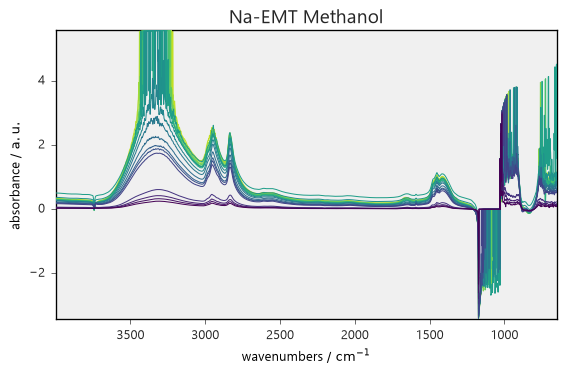

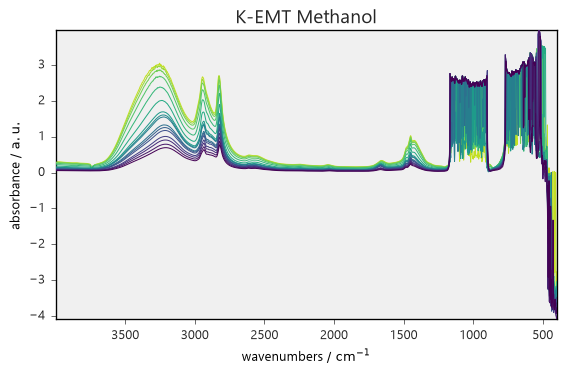

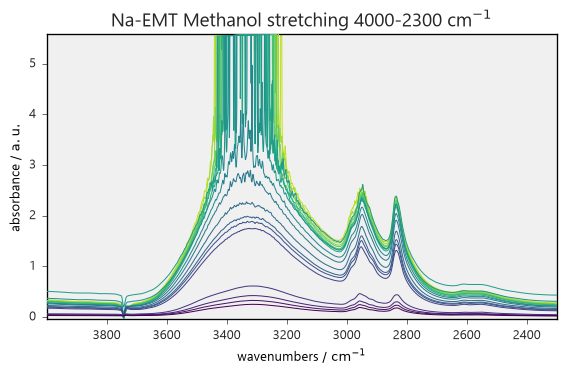

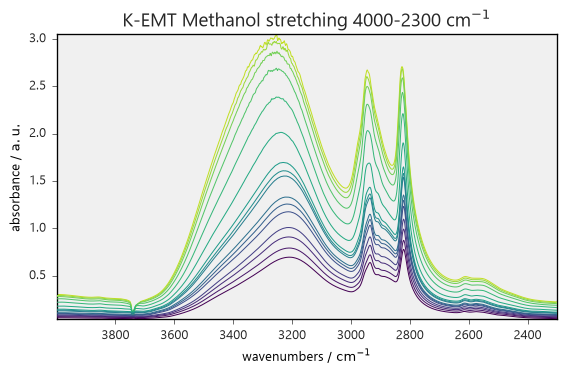

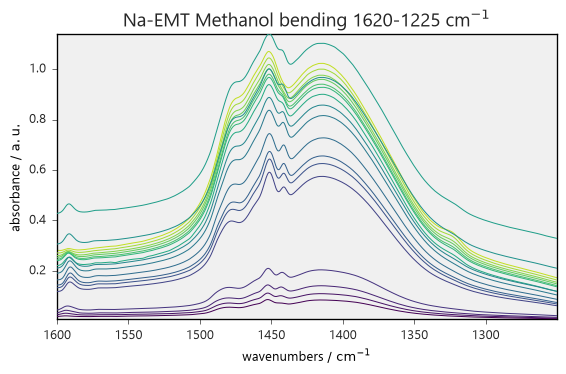

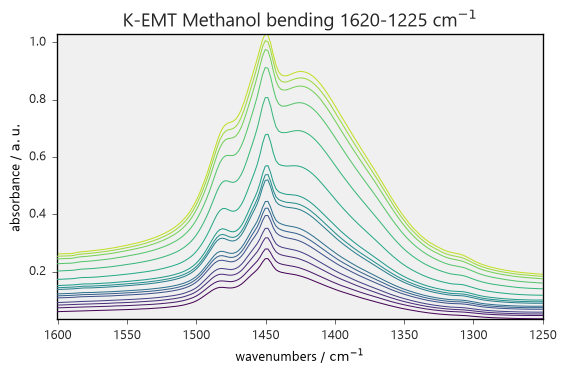

In [113]:
D_Na.plot(title='Na-EMT Methanol')
D_K.plot(title='K-EMT Methanol')
D_Nastretching = D_Na[:, 4000.:2300.]
D_Kstretching = D_K[:, 4000.:2300.]
D_Nastretching.plot(title='Na-EMT Methanol stretching 4000-2300 cm$^{-1}$')
D_Kstretching.plot(title='K-EMT Methanol stretching 4000-2300 cm$^{-1}$')
D_Nabending = D_Na[:, 1600.:1250.]
D_Kbending = D_K[:, 1600.:1250.]
D_Nabending.plot(title='Na-EMT Methanol bending 1620-1225 cm$^{-1}$')
D_Kbending.plot(title='K-EMT Methanol bending 1620-1225 cm$^{-1}$')

### Baseline of the bending region
Fits a linear baseline to the bending region of each sample, using the anchor ranges set in the cell, and plots the corrected spectra with their baselines.


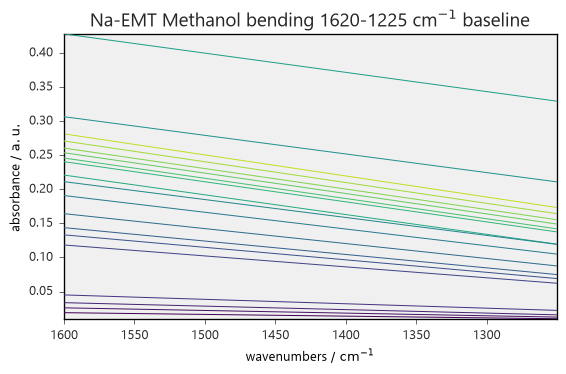

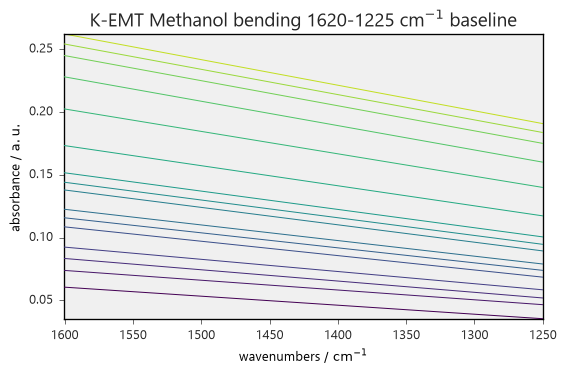

In [114]:
blc = scp.Baseline(model="polynomial", order=1)
#blc.ranges = [[4000., 3900.], [2300., 2350.]]
_ = blc.fit(D_Nabending)

D_Nabending_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='Na-EMT Methanol bending 1620-1225 cm$^{-1}$ baseline')

_ = blc.fit(D_Kbending)
D_Kbending_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='K-EMT Methanol bending 1620-1225 cm$^{-1}$ baseline')

### Na-EMT bending peaks
Plots the baseline-corrected bending region and labels the peaks found in the last (highest-dose) spectrum. The figure is saved as SVG.

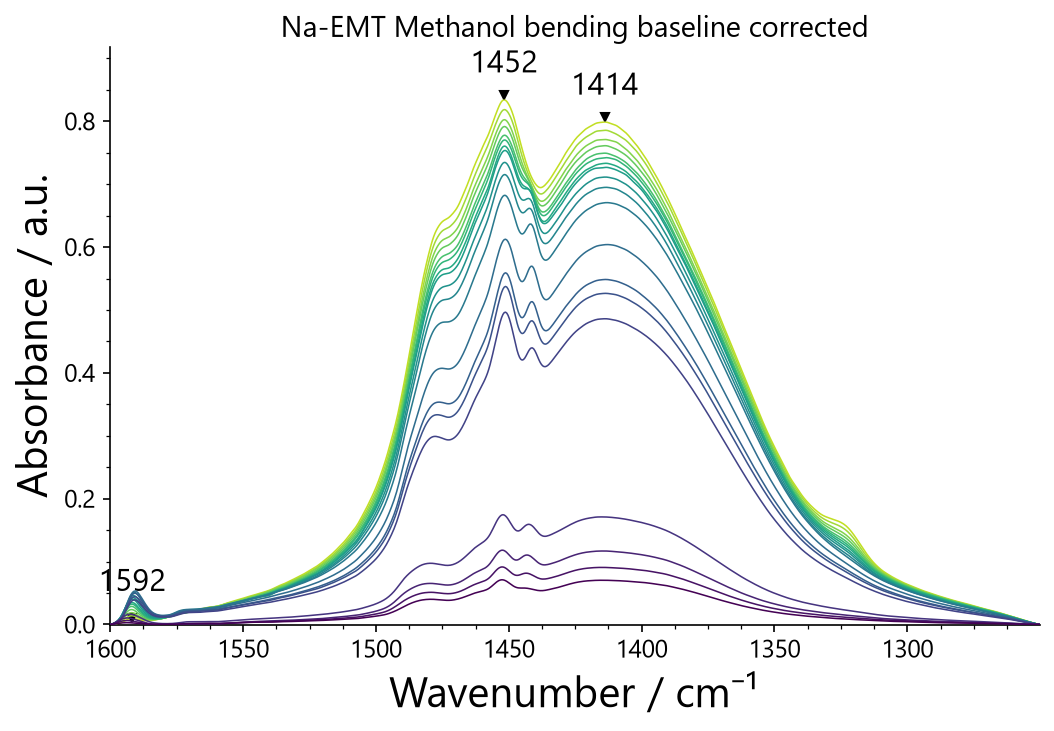

In [115]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Nabending_corrected.plot(ax=ax, title="Na-EMT Methanol bending baseline corrected")

spectrum = D_Nabending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="1 cm^-1", prominence=0.001)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Nabending_corrected.data), np.max(D_Nabending_corrected.data) + 0.1*np.max(D_Nabending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT_methanol_bending_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT bending peaks
Same as above for K-EMT.

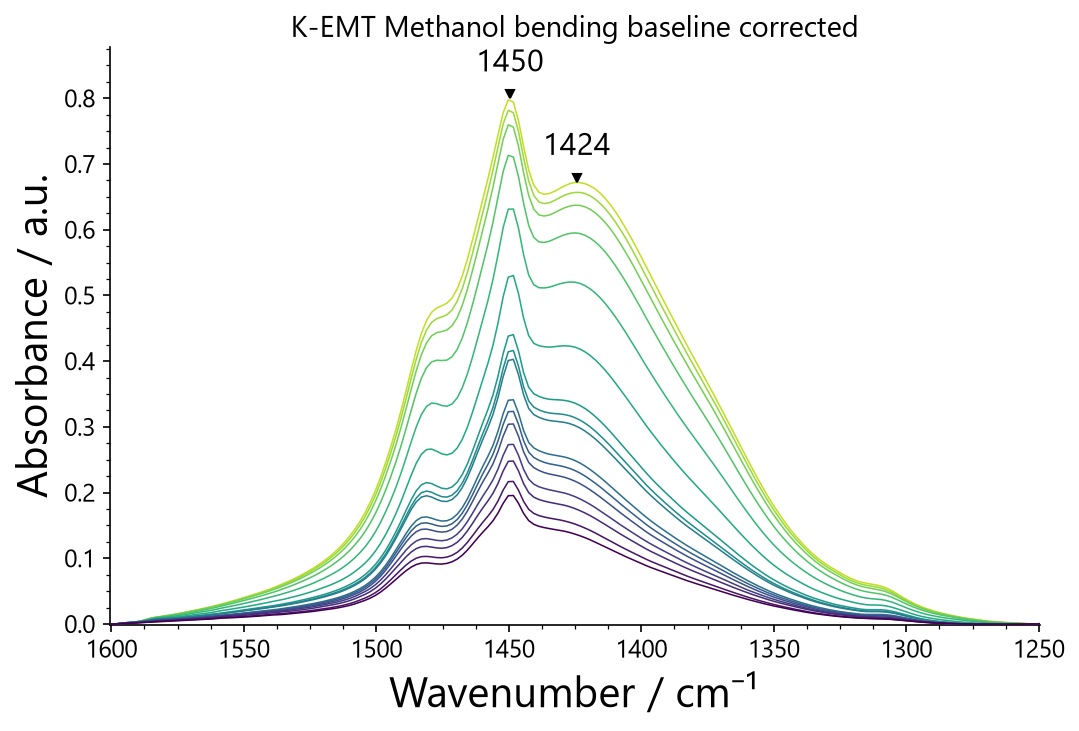

In [116]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Kbending_corrected.plot(ax=ax, title="K-EMT Methanol bending baseline corrected")

spectrum = D_Kbending_corrected[-1]
peaks, props = spectrum.find_peaks(distance="1 cm^-1", prominence=0.01)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 10), textcoords="offset points", rotation=0, va="bottom",
                ha="center", fontsize=15)

ax.set_ylim(np.min(D_Kbending_corrected.data), np.max(D_Kbending_corrected.data) + 0.1*np.max(D_Kbending_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT_methanol_bending_corrected.svg", format="svg", bbox_inches="tight")

### Baseline of the CH stretching region
Fits a linear baseline over 3020–2755 cm⁻¹ for each sample and plots the baselines. The corrected spectra are used for the area integration.

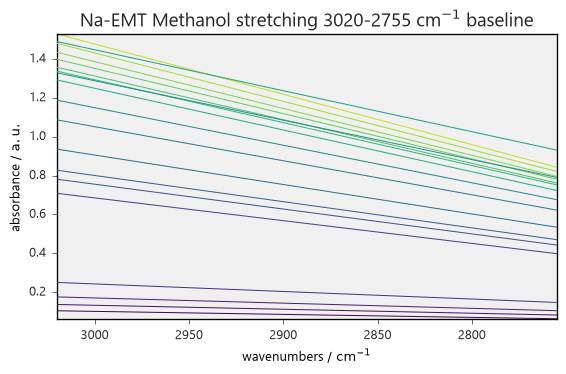

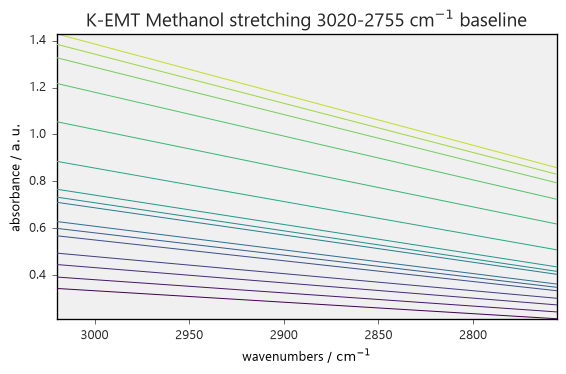

In [117]:
blc = scp.Baseline(model="polynomial", order=1)
_ = blc.fit(D_Nastretching[:,3020.:2755.])

D_NastretchingCH_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='Na-EMT Methanol stretching 3020-2755 cm$^{-1}$ baseline')

_ = blc.fit(D_Kstretching[:,3020.:2755.])
D_KstretchingCH_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot(title='K-EMT Methanol stretching 3020-2755 cm$^{-1}$ baseline')

### Na-EMT CH stretching peaks
Plots the baseline-corrected CH stretching band and labels the peaks of the last spectrum. The figure is saved as SVG.

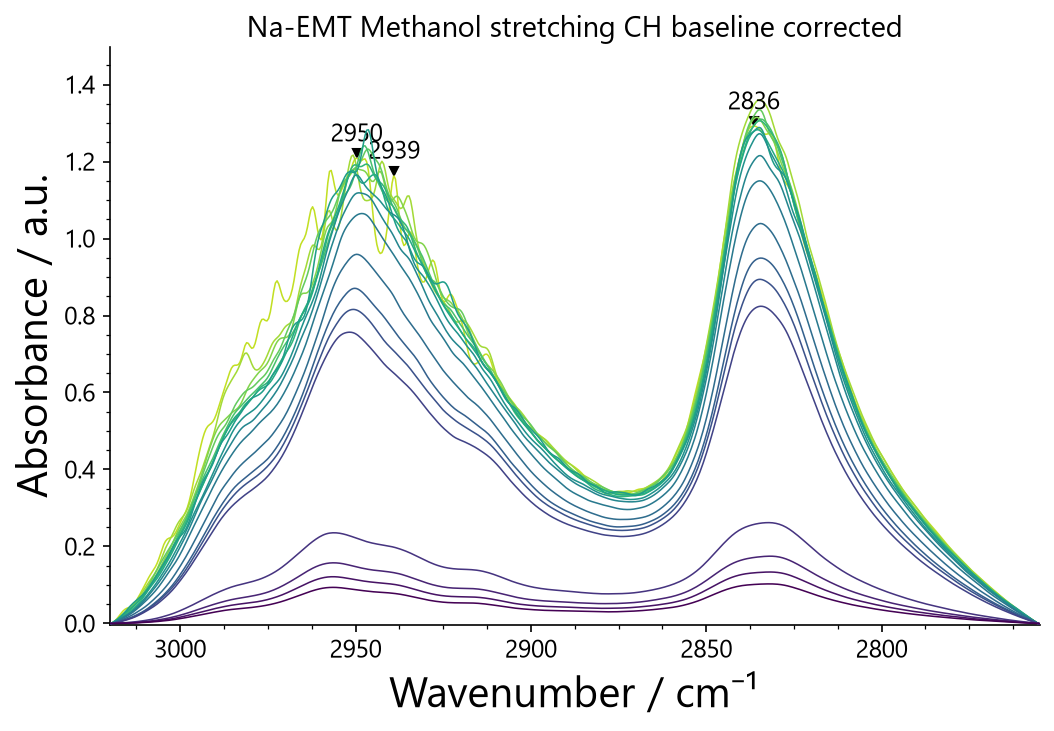

In [118]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_NastretchingCH_corrected.plot(ax=ax, title="Na-EMT Methanol stretching CH baseline corrected")

spectrum = D_NastretchingCH_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_NastretchingCH_corrected.data), np.max(D_NastretchingCH_corrected.data) + 0.1*np.max(D_NastretchingCH_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT-methanolstretchingCH_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT CH stretching peaks
Same as above for K-EMT.

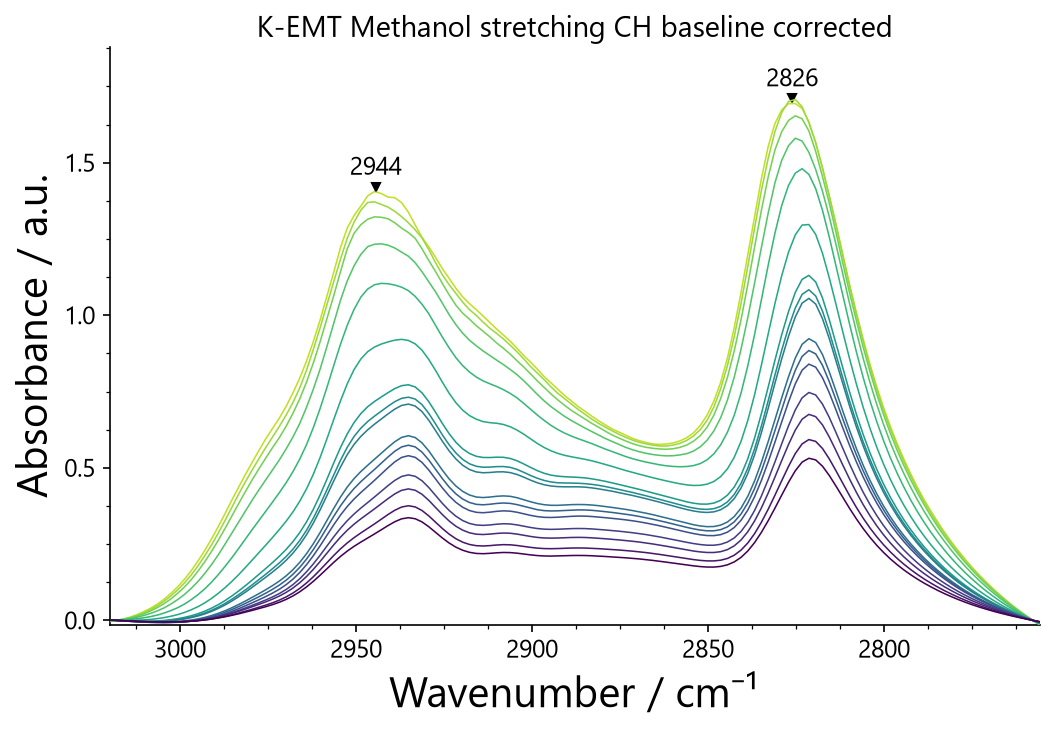

In [119]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_KstretchingCH_corrected.plot(ax=ax, title="K-EMT Methanol stretching CH baseline corrected")

spectrum = D_KstretchingCH_corrected[-1]
peaks, props = spectrum.find_peaks(distance="5 cm^-1", prominence=0.1)

xs = np.asarray(peaks.x.data, dtype=float)
ys = np.asarray(peaks.data, dtype=float)

ax.plot(xs, ys + 0.01*ys, "v", color="black", markersize=4)
for x, y in zip(xs, ys):
    ax.annotate(f"{x:.0f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=12)

ax.set_ylim(np.min(D_KstretchingCH_corrected.data), np.max(D_KstretchingCH_corrected.data) + 0.1*np.max(D_KstretchingCH_corrected.data))
ax.set_xlabel("Wavenumber / cm⁻¹")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT-methanolstretchingCH_corrected.svg", format="svg", bbox_inches="tight")

### Integrate the CH stretching band
Integrates each corrected CH stretching spectrum with the trapezoidal rule to obtain one area per dose, for Na-EMT and K-EMT.

In [120]:
area_Na_methanolstretchingCH = D_NastretchingCH_corrected.trapezoid(dim="x")
area_K_methanolstretchingCH = D_KstretchingCH_corrected.trapezoid(dim="x")

### Na-EMT isotherm
Converts the equivalent pressures from Torr to Pa and plots the CH stretching area against pressure. The figure is saved as SVG.

dose 0   idx 1         8.93 Pa   (unit used: torr)
dose 0   idx 2         9.33 Pa   (unit used: torr)
dose 0   idx 3         9.87 Pa   (unit used: torr)
dose 0   idx 4        10.40 Pa   (unit used: torr)
dose 0   idx 5        10.67 Pa   (unit used: torr)
dose 0   idx 6        11.33 Pa   (unit used: torr)
dose 0   idx 7        12.00 Pa   (unit used: torr)
dose 0   idx 8        14.27 Pa   (unit used: torr)
dose 0   idx 9        37.60 Pa   (unit used: torr)
dose 0   idx 10       97.46 Pa   (unit used: torr)
dose 0   idx 11      184.25 Pa   (unit used: torr)
dose 0   idx 12      338.64 Pa   (unit used: torr)
dose 0   idx 13      498.62 Pa   (unit used: torr)
dose 0   idx 14      723.94 Pa   (unit used: torr)
dose 0   idx 15      994.58 Pa   (unit used: torr)
dose 0   idx 16     1490.54 Pa   (unit used: torr)
dose 0   idx 17     2031.83 Pa   (unit used: torr)
dose 0   idx 18     2934.42 Pa   (unit used: torr)
dose 0   idx 19     4366.30 Pa   (unit used: torr)


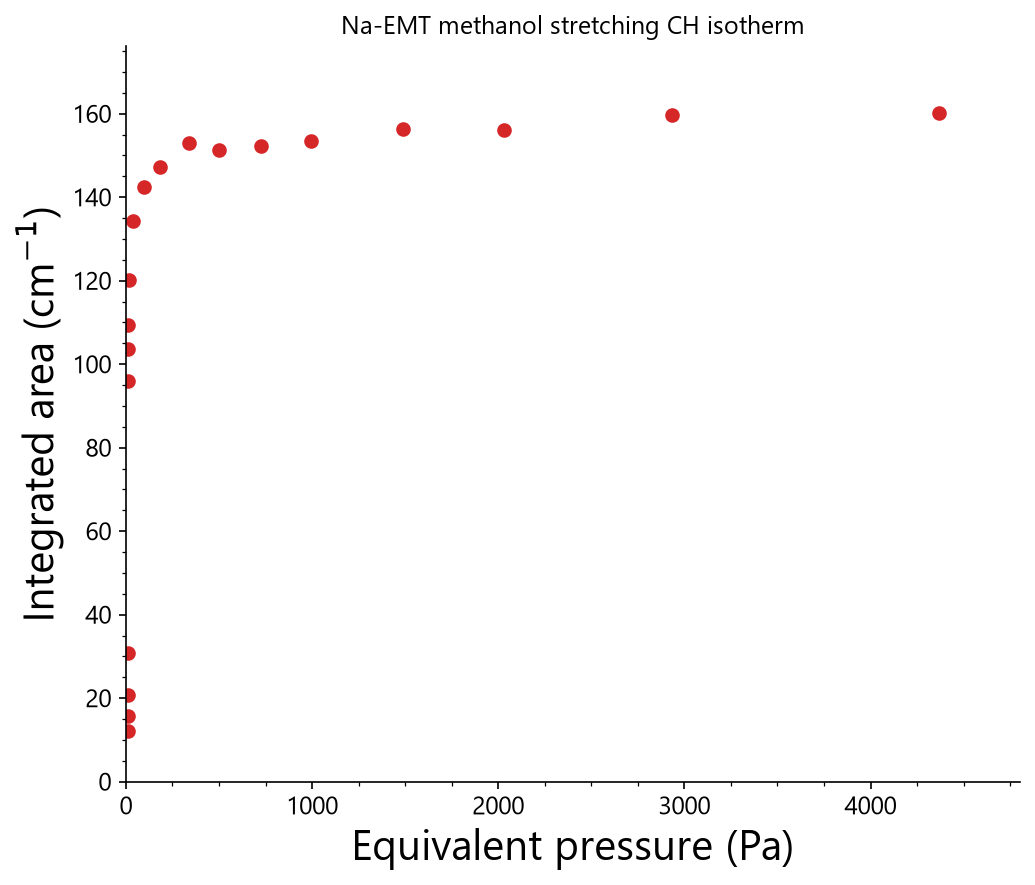

In [121]:
names_Na, x_Na = pressures_from_filenames(data_Na)

y_Na = np.abs(np.asarray(area_Na_methanolstretchingCH.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_Na, y_Na, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"Na-EMT methanol stretching CH isotherm")
ax1.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
ax1.set_ylim(0, max(y_Na) + 0.1*max(y_Na))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT-methanol_stretching_CH_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### K-EMT isotherm
Converts the equivalent pressures from mbar to Pa and plots the CH stretching area against pressure. The figure is saved as SVG.


dose 0   idx 1         6.90 Pa   (unit used: mbar)
dose 0   idx 2         7.40 Pa   (unit used: mbar)
dose 0   idx 3         8.00 Pa   (unit used: mbar)
dose 0   idx 4         8.60 Pa   (unit used: mbar)
dose 0   idx 5        10.90 Pa   (unit used: mbar)
dose 0   idx 6        11.40 Pa   (unit used: mbar)
dose 0   idx 7        12.10 Pa   (unit used: mbar)
dose 0   idx 8        12.70 Pa   (unit used: mbar)
dose 0   idx 9        13.30 Pa   (unit used: mbar)
dose 0   idx 10       13.90 Pa   (unit used: mbar)
dose 0   idx 11       15.00 Pa   (unit used: mbar)
dose 0   idx 12       19.30 Pa   (unit used: mbar)
dose 0   idx 13       42.90 Pa   (unit used: mbar)
dose 0   idx 14      113.20 Pa   (unit used: mbar)
dose 0   idx 15      201.70 Pa   (unit used: mbar)
dose 0   idx 16      316.50 Pa   (unit used: mbar)


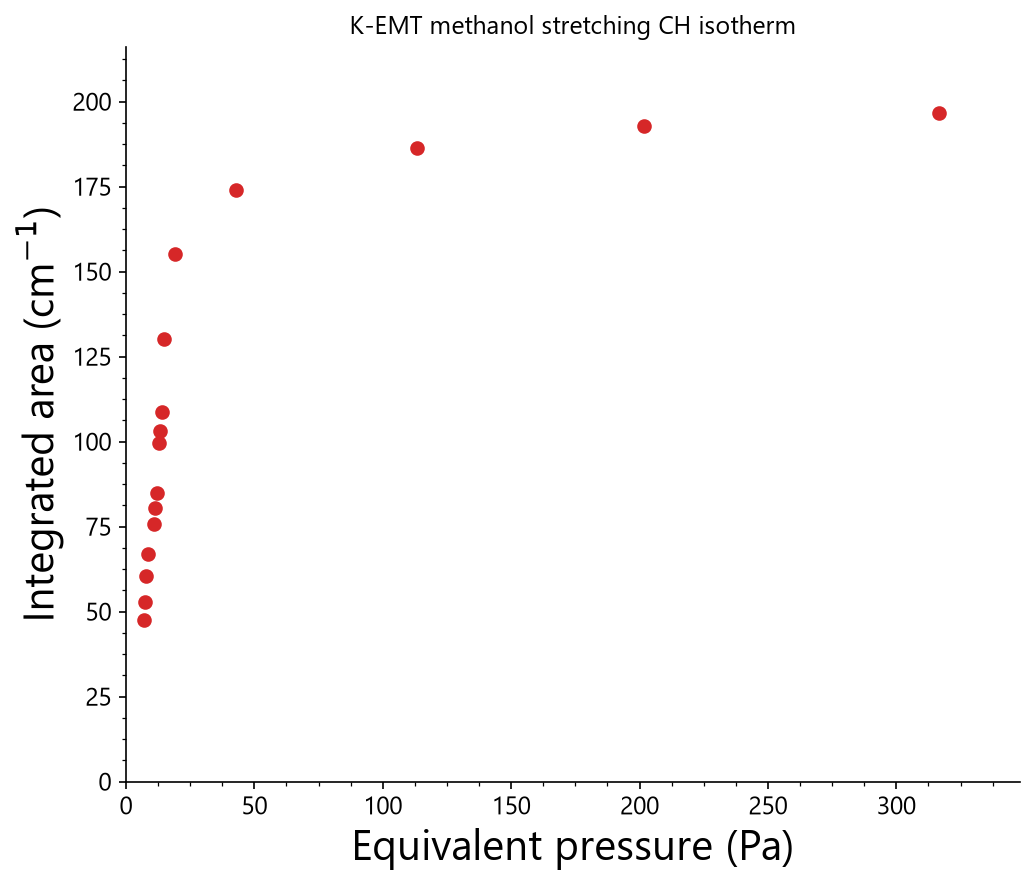

In [122]:
names_K, x_K = pressures_from_filenames(data_K)

y_K = np.abs(np.asarray(area_K_methanolstretchingCH.data)).ravel()

fig, ax1 = plt.subplots(1, 1, figsize=(7, 6))
ax1.plot(x_K, y_K, "o", color="C3")
ax1.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax1.set_xlabel("Equivalent pressure (Pa)")
ax1.set_title(f"K-EMT methanol stretching CH isotherm")
ax1.set_xlim(0, max(x_K) + 0.1*max(x_K))
ax1.set_ylim(0, max(y_K) + 0.1*max(y_K))
add_minor_ticks(ax1)
fig.tight_layout()
fig.savefig(outputpath / "K-EMT-methanol_stretching_CH_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Na-EMT vs K-EMT isotherms
Plots both isotherms on the same axes to compare the two samples. The x axis spans the full K-EMT pressure range.

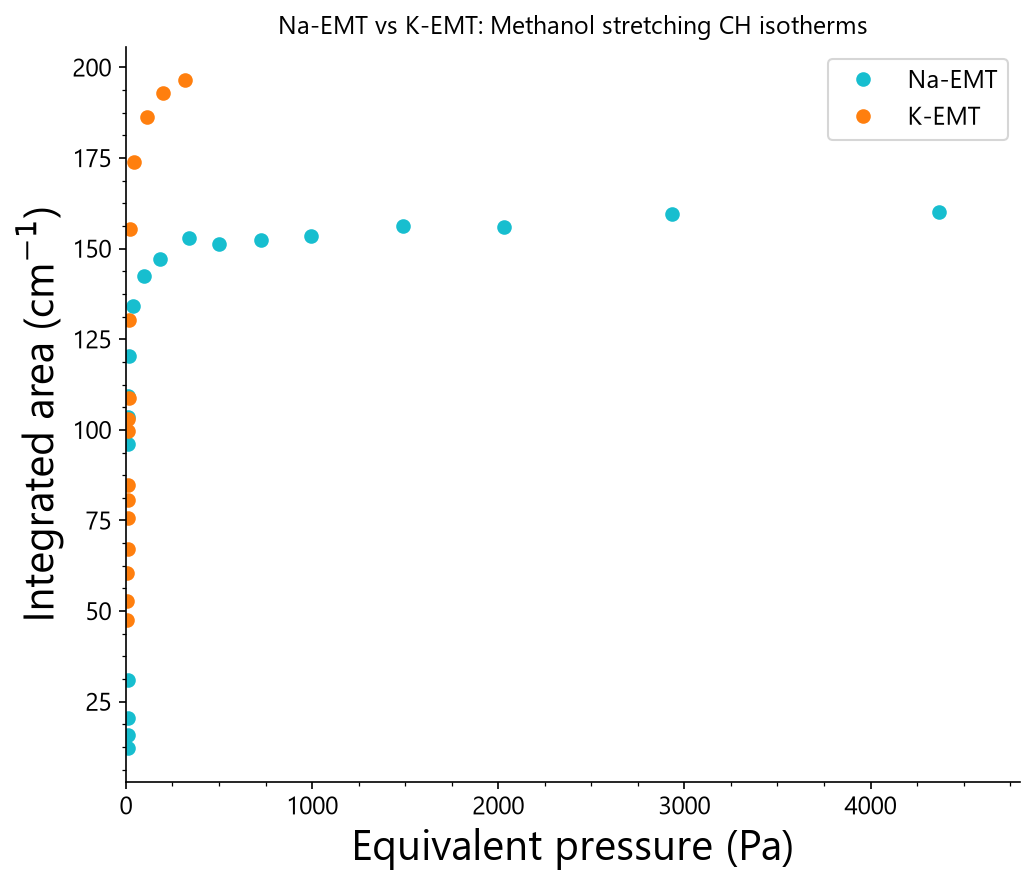

In [123]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na[:n_Na], y_Na[:n_Na], "o", color="C9", label="Na-EMT")
ax.plot(x_K[:n_K], y_K[:n_K], "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: Methanol stretching CH isotherms")
ax.set_xlim(0, max(x_Na) + 0.1*max(x_Na))
add_minor_ticks(ax)
ax.legend(loc="best")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-methanol_isotherm.svg", format="svg", bbox_inches="tight")
plt.show()

### Isotherm comparison, low-pressure zoom
Same plot as above, with the x axis limited to the Na-EMT pressure range so the low-pressure region is readable.

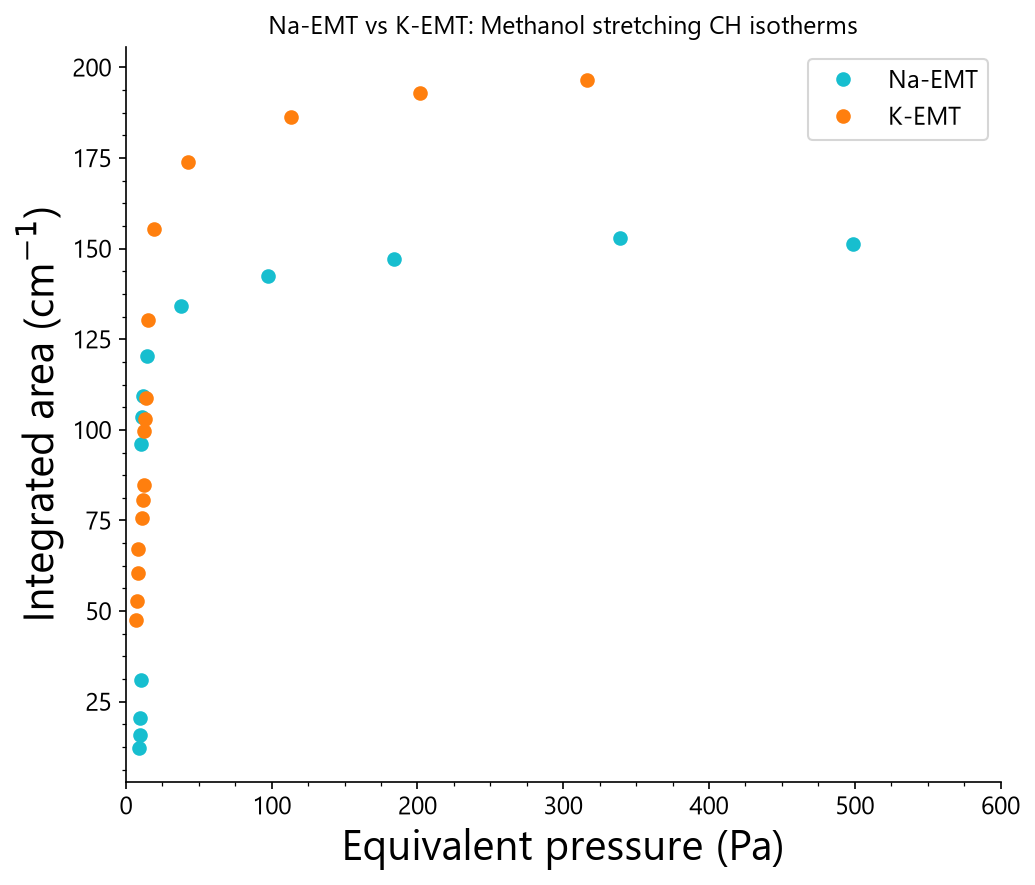

In [124]:
n = 19 # number of points to zoom in
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(x_Na[:n], y_Na[:n], "o", color="C9", label="Na-EMT")
ax.plot(x_K[:n], y_K[:n], "o", color="C1", label="K-EMT")
ax.set_ylabel(r"Integrated area (cm$^{-1}$)")
ax.set_xlabel("Equivalent pressure (Pa)")
ax.set_title(f"Na-EMT vs K-EMT: Methanol stretching CH isotherms")
ax.set_xlim(0, 600)
add_minor_ticks(ax)
ax.legend(loc="best")
add_minor_ticks(ax)
fig.tight_layout()
fig.savefig(outputpath / "Na-EMT_vs_K-EMT-methanol_isotherm zoom in.svg", format="svg", bbox_inches="tight")
plt.show()

### Baseline of the full stretching region
Fits a linear baseline over the whole stretching region (4000–2300 cm⁻¹) for each sample, to show the OH and CH bands together.

INFO | This coordinate (4000.0) is outside the axis limits (649.921-3999.81).
The closest limit index is returned
INFO | This coordinate (4000.0) is outside the axis limits (2299.794-3999.81).
The closest limit index is returned
INFO | This coordinate (4000.0) is outside the axis limits (399.193-3999.64).
The closest limit index is returned
INFO | This coordinate (2300.0) is outside the axis limits (2300.661-3999.64).
The closest limit index is returned
INFO | This coordinate (4000.0) is outside the axis limits (2300.661-3999.64).
The closest limit index is returned


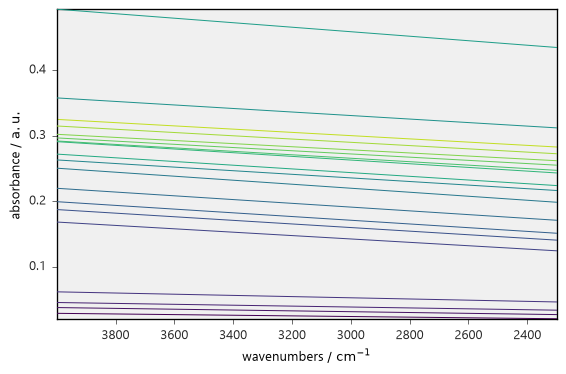

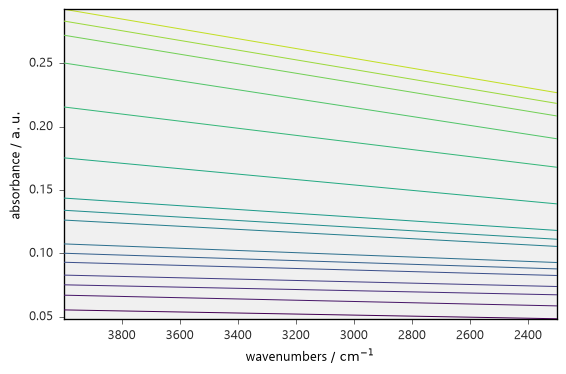

In [125]:
blc = scp.Baseline(model="polynomial", order=1)
blc.ranges = [[4000., 3900.], [2300., 2350.]]
_ = blc.fit(D_Na[:, 4000.:2300.])

D_Na_stretching_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot()

_ = blc.fit(D_K[:, 4000.:2300.])
D_K_stretching_corrected = blc.corrected
baseline = blc.baseline
_ = baseline.plot()

### Na-EMT stretching region peaks
Plots the corrected spectra and labels the band positions of the last spectrum. Positive peaks get a triangle above and negative peaks a triangle below. Only dips below the baseline are kept, so the valleys between bands are not labelled.

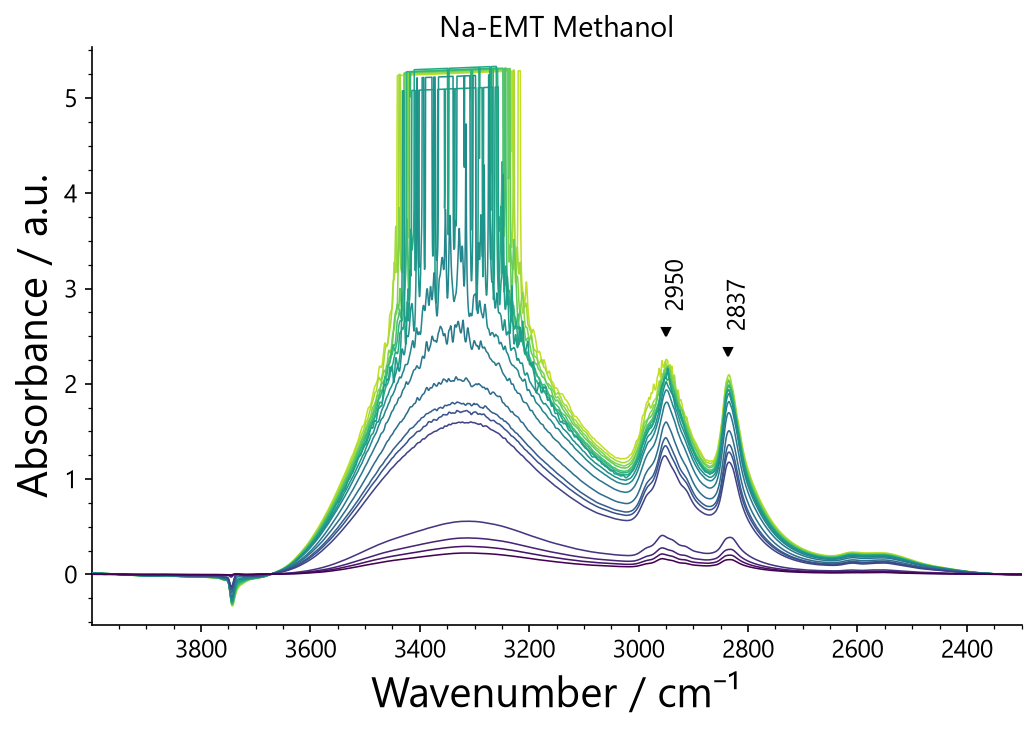

In [126]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_Na_stretching_corrected.plot(ax=ax, title="Na-EMT Methanol")

spectrum = D_Na_stretching_corrected[-1]

pos, _ = spectrum.find_peaks(distance="5 cm^-1", prominence=0.25)
neg, _ = (-spectrum).find_peaks(distance="5 cm^-1", prominence=0.01)

xp = np.asarray(pos.x.data, dtype=float)
yp = np.asarray(pos.data, dtype=float)
xn = np.asarray(neg.x.data, dtype=float)
yn = -np.asarray(neg.data, dtype=float)

# keep only dips that go below the baseline (drops the 3025 / 2870 valleys)
keep = yn < -0.05
xn, yn = xn[keep], yn[keep]

span = np.max(D_Na_stretching_corrected.data) - np.min(D_Na_stretching_corrected.data)
off = 0.05 * span                            # marker offset in data units

ax.plot(xp, yp + off, "v", color="black", markersize=4)   # positive: triangle above
ax.plot(xn, yn - off, "^", color="black", markersize=4)   # negative: triangle below

for x, y in zip(xp, yp):
    ax.annotate(f"{x:.0f}", (x, y + off), xytext=(5, 10), textcoords="offset points", rotation = 90,
                ha="center", va="bottom", fontsize=12)
for x, y in zip(xn, yn):
    ax.annotate(f"{x:.0f}", (x, y - off), xytext=(0, -5), textcoords="offset points",
                ha="right", va="top", fontsize=12)

ax.set_ylim(np.min(D_Na_stretching_corrected.data) - 0.2, np.max(D_Na_stretching_corrected.data) + 0.2)
ax.set_xlabel("Wavenumber / cm\u207b\u00b9")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "Na-EMT-methanol_stretching_corrected.svg", format="svg", bbox_inches="tight")

### K-EMT stretching region peaks
Same as above for K-EMT.

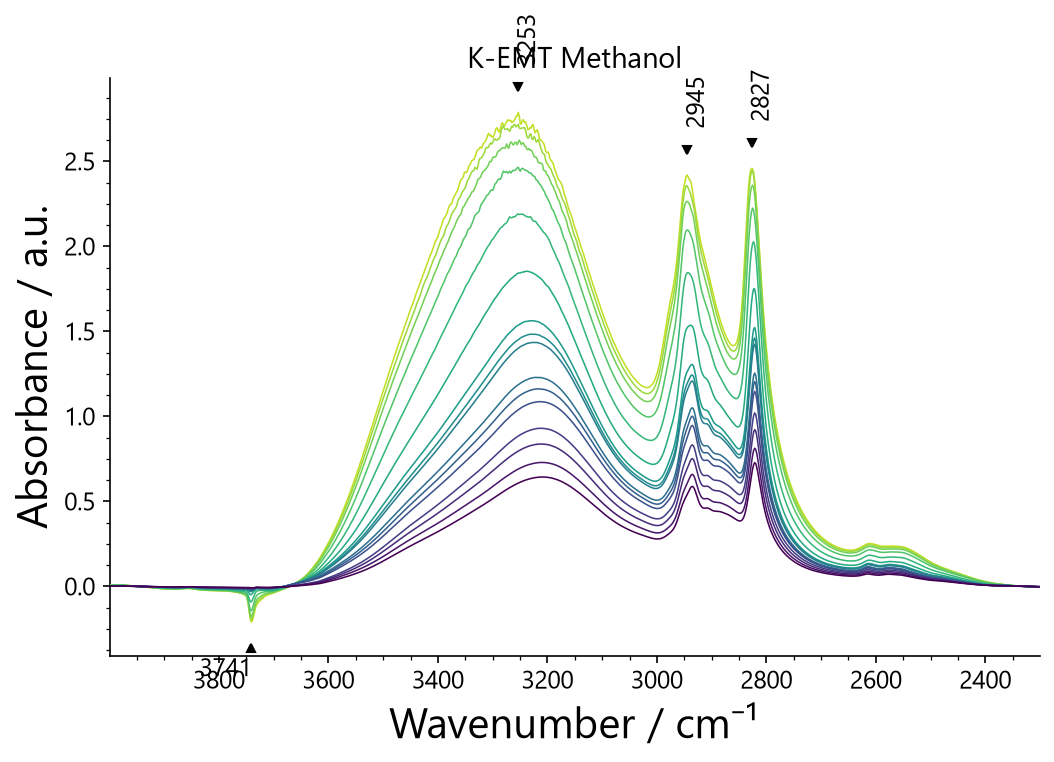

In [127]:
fig, ax = plt.subplots(figsize=(8, 5))
_ = D_K_stretching_corrected.plot(ax=ax, title="K-EMT Methanol")

spectrum = D_K_stretching_corrected[-1]

pos, _ = spectrum.find_peaks(distance="5 cm^-1", prominence=0.25)
neg, _ = (-spectrum).find_peaks(distance="5 cm^-1", prominence=0.01)

xp = np.asarray(pos.x.data, dtype=float)
yp = np.asarray(pos.data, dtype=float)
xn = np.asarray(neg.x.data, dtype=float)
yn = -np.asarray(neg.data, dtype=float)

# keep only dips that go below the baseline (drops the 3025 / 2870 valleys)
keep = yn < -0.05
xn, yn = xn[keep], yn[keep]


span = np.max(D_K_stretching_corrected.data) - np.min(D_K_stretching_corrected.data)
off = 0.05 * span                            # marker offset in data units

ax.plot(xp, yp + off, "v", color="black", markersize=4)   # positive: triangle above
ax.plot(xn, yn - off, "^", color="black", markersize=4)   # negative: triangle below

for x, y in zip(xp, yp):
    ax.annotate(f"{x:.0f}", (x, y + off), xytext=(5, 10), textcoords="offset points", rotation = 90,
                ha="center", va="bottom", fontsize=12)
for x, y in zip(xn, yn):
    ax.annotate(f"{x:.0f}", (x, y - off), xytext=(0, -5), textcoords="offset points",
                ha="right", va="top", fontsize=12)

ax.set_ylim(np.min(D_K_stretching_corrected.data) - 0.2, np.max(D_K_stretching_corrected.data) + 0.2)
ax.set_xlabel("Wavenumber / cm\u207b\u00b9")
ax.set_ylabel("Absorbance / a.u.")
add_minor_ticks(ax)

fig.savefig(outputpath / "K-EMT-methanol_stretching_corrected.svg", format="svg", bbox_inches="tight")

In [128]:
x_Na = np.asarray(x_Na, dtype=float).ravel()
y_Na = np.asarray(y_Na, dtype=float).ravel()
x_K = np.asarray(x_K, dtype=float).ravel()
y_K = np.asarray(y_K, dtype=float).ravel()

assert len(x_Na) == len(y_Na), (len(x_Na), len(y_Na))
assert len(x_K) == len(y_K), (len(x_K), len(y_K))

def make_isotherm_table(x, y):
    return pd.DataFrame({
        "Spectrum": np.arange(1, len(x) + 1),
        "Pressure / Pa": x.round(3),
        "Integrated area / cm\u2212\u00b9": y.round(3),
    })

table_Na = make_isotherm_table(x_Na, y_Na)
table_K = make_isotherm_table(x_K, y_K)

display(table_Na); display(table_K)

save_area_sheet({"Na-EMT": table_Na, "K-EMT": table_K}, "Isotherm",
                outputpath / "x-EMT-isotherm.xlsx", gap=1)

,Spectrum,Pressure / Pa,Integrated area / cm−¹
0,1,8.933,12.168
1,2,9.333,15.819
2,3,9.866,20.636
3,4,10.399,30.889
4,5,10.666,96.079
5,6,11.332,103.613
6,7,11.999,109.451
7,8,14.265,120.261
8,9,37.597,134.218
9,10,97.458,142.371


,Spectrum,Pressure / Pa,Integrated area / cm−¹
0,1,6.9,47.412
1,2,7.4,52.871
2,3,8.0,60.611
3,4,8.6,67.082
4,5,10.9,75.772
5,6,11.4,80.567
6,7,12.1,84.918
7,8,12.7,99.735
8,9,13.3,103.028
9,10,13.9,108.798
